# AURA: Hospital Energy Consumption — Exploratory Data Analysis (EDA)
**Facility:** HOSPITAL_001 | **Source Dataset:** `data/energy.csv`
**Objective:** Rigorous Exploratory Data Analysis on 90 days (43,200 intervals) of hospital power telemetry to discover baseline profiles, time dynamics, zone disparities, occupancy correlation, and anomaly behavior prior to model selection.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Styling
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['font.size'] = 11

DATA_PATH = Path("../data/energy.csv")
print("Libraries imported and configuration ready.")


Libraries imported and configuration ready.


## 1. Basic Data Understanding
Loading dataset, checking dimensions, data types, timestamp range, unique zones, operational statuses, energy sources, missing values, and duplicates.


In [3]:
# Load energy dataset
df = pd.read_csv(DATA_PATH)

print(f"Total Rows: {len(df):,}")
print(f"Total Columns: {len(df.columns)}")
print("\nColumn Data Types:")
print(df.dtypes)

# Parse timestamps (dayfirst=True for DD-MM-YYYY HH:MM)
df['datetime'] = pd.to_datetime(df['timestamp'], dayfirst=True)

print(f"\nDate Range: {df['datetime'].min()} to {df['datetime'].max()} ({(df['datetime'].max() - df['datetime'].min()).days} days)")
print(f"Unique Zones ({df['zone_id'].nunique()}): {df['zone_id'].unique().tolist()}")
print(f"Unique Operational Statuses ({df['operational_status'].nunique()}): {df['operational_status'].unique().tolist()}")
print(f"Unique Energy Sources ({df['energy_source'].nunique()}): {df['energy_source'].unique().tolist()}")
print(f"\nMissing Values:\n{df.isnull().sum()}")
print(f"\nDuplicate Rows: {df.duplicated().sum()}")


Total Rows: 43,200
Total Columns: 10

Column Data Types:
timestamp                 str
facility_id               str
zone_id                   str
energy_kwh            float64
occupancy_percent     float64
temperature_c         float64
operational_status        str
energy_source             str
source                    str
anomaly_flag            int64
dtype: object

Date Range: 2026-01-01 00:00:00 to 2026-03-31 23:45:00 (89 days)
Unique Zones (5): ['ICU', 'Emergency', 'General_Ward', 'OPD', 'Admin']
Unique Operational Statuses (4): ['NORMAL', 'REDUCED_OPERATION', 'EMERGENCY', 'MAINTENANCE']
Unique Energy Sources (3): ['GRID', 'BACKUP_GENERATOR', 'SOLAR']

Missing Values:
timestamp             0
facility_id           0
zone_id               0
energy_kwh            0
occupancy_percent     0
temperature_c         0
operational_status    0
energy_source         0
source                0
anomaly_flag          0
datetime              0
dtype: int64

Duplicate Rows: 0


## 2. Descriptive Statistics
Detailed summary statistics for `energy_kwh` (including 1st, 5th, 25th, 50th, 75th, 95th, 99th percentiles), alongside `occupancy_percent` and `temperature_c`.


In [5]:
# Descriptive statistics for energy_kwh
energy_stats = df['energy_kwh'].describe(percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99])
print("=== ENERGY_KWH SUMMARY STATISTICS ===")
print(energy_stats.round(2))

print("\n=== OCCUPANCY & TEMPERATURE SUMMARY ===")
print(df[['occupancy_percent', 'temperature_c']].describe().round(2))


=== ENERGY_KWH SUMMARY STATISTICS ===
count    43200.00
mean       108.44
std         79.64
min         10.07
1%          10.33
5%          11.07
25%         24.98
50%        112.28
75%        178.43
95%        227.37
99%        236.28
max        420.31
Name: energy_kwh, dtype: float64

=== OCCUPANCY & TEMPERATURE SUMMARY ===
       occupancy_percent  temperature_c
count           43200.00       43200.00
mean               52.58          27.52
std                34.18           4.83
min                 0.00          18.00
25%                 3.50          23.20
50%                65.10          27.50
75%                81.10          31.90
max               100.00          37.10


## 3. Energy Distribution Analysis
Histogram and KDE of `energy_kwh` to determine whether consumption is normal, skewed, or multimodal.


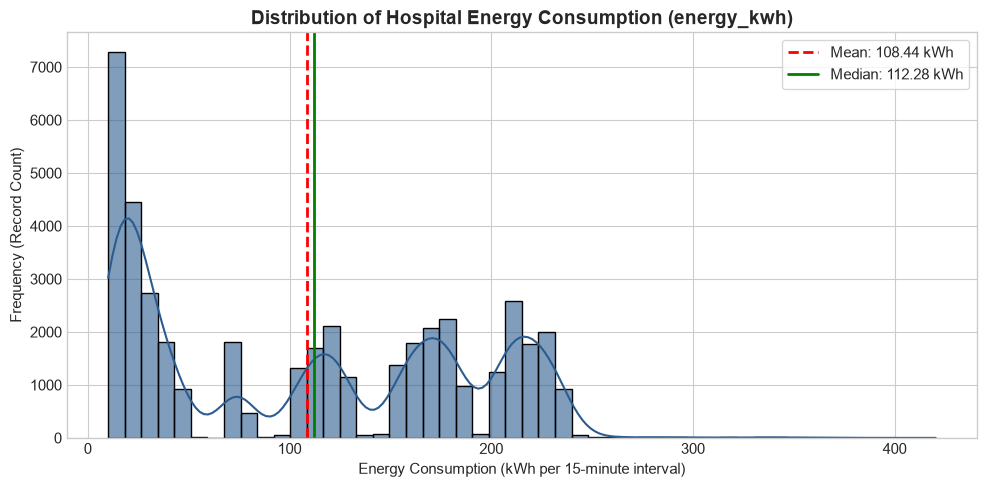

In [7]:
fig, ax = plt.subplots(figsize=(10, 5))
sns.histplot(df['energy_kwh'], bins=50, kde=True, color='#2b5c8f', edgecolor='black', alpha=0.6, ax=ax)
ax.axvline(df['energy_kwh'].mean(), color='red', linestyle='--', linewidth=2, label=f"Mean: {df['energy_kwh'].mean():.2f} kWh")
ax.axvline(df['energy_kwh'].median(), color='green', linestyle='-', linewidth=2, label=f"Median: {df['energy_kwh'].median():.2f} kWh")

ax.set_title("Distribution of Hospital Energy Consumption (energy_kwh)", fontsize=14, fontweight='bold')
ax.set_xlabel("Energy Consumption (kWh per 15-minute interval)")
ax.set_ylabel("Frequency (Record Count)")
ax.legend(frameon=True)
plt.tight_layout()
plt.show()


**Distribution Interpretation:**
- The distribution is distinctly **multimodal** (multiple distinct peaks) rather than a bell curve.
- One peak exists at **10–35 kWh** (Administrative and OPD areas).
- A second cluster centers near **100–120 kWh** (General Ward inpatient care).
- A third heavy cluster spans **170–240 kWh** (Emergency Room and ICU life support).
- Values above 300 kWh represent high-intensity emergency surgical operations and controlled synthetic anomaly periods.


## 4. Time Trend Analysis (Daily Aggregated Energy)
Aggregating the 15-minute telemetry into daily totals over the 90-day simulation to inspect overall facility consumption continuity and major spikes.


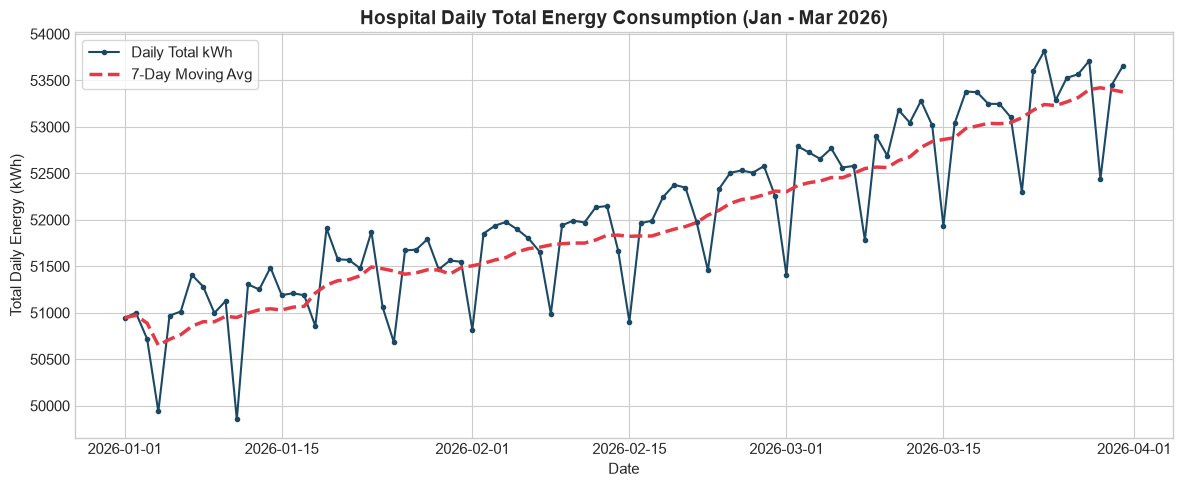

In [10]:
# Group daily total energy
df['date'] = df['datetime'].dt.date
daily_energy = df.groupby('date')['energy_kwh'].sum().reset_index()
daily_energy['date'] = pd.to_datetime(daily_energy['date'])
daily_energy['7d_rolling'] = daily_energy['energy_kwh'].rolling(window=7, min_periods=1).mean()

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(daily_energy['date'], daily_energy['energy_kwh'], color='#1b4965', linewidth=1.5, marker='o', markersize=3, label='Daily Total kWh')
ax.plot(daily_energy['date'], daily_energy['7d_rolling'], color='#e63946', linewidth=2.5, linestyle='--', label='7-Day Moving Avg')

ax.set_title("Hospital Daily Total Energy Consumption (Jan - Mar 2026)", fontsize=14, fontweight='bold')
ax.set_xlabel("Date")
ax.set_ylabel("Total Daily Energy (kWh)")
ax.legend(frameon=True)
plt.tight_layout()
plt.show()


## 5. Hourly Pattern (24-Hour Hospital Cycle)
Extracting the hour from timestamps and calculating average energy consumption across all 24 hours of the day.


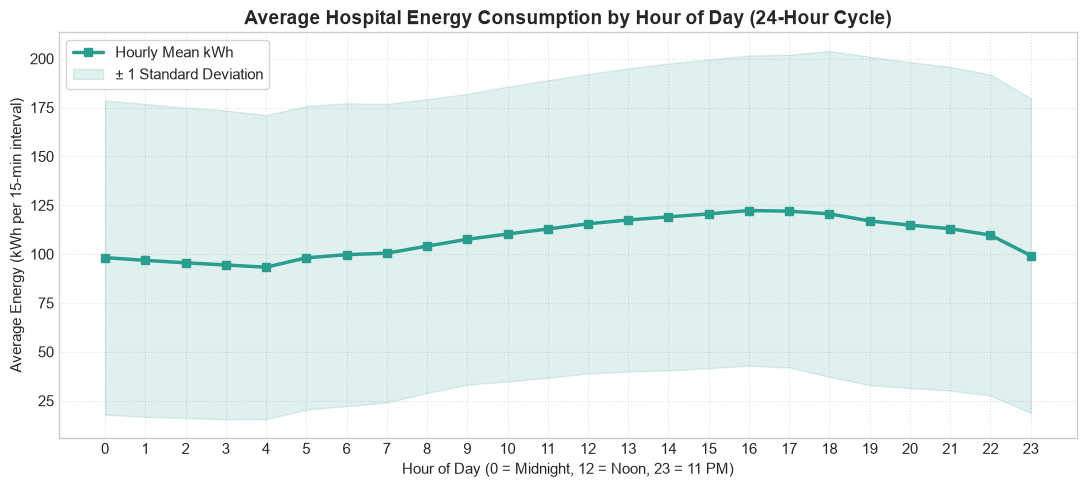

In [12]:
df['hour'] = df['datetime'].dt.hour
hourly_stats = df.groupby('hour')['energy_kwh'].agg(['mean', 'std']).reset_index()

fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(hourly_stats['hour'], hourly_stats['mean'], marker='s', color='#2a9d8f', linewidth=2.5, label='Hourly Mean kWh')
ax.fill_between(hourly_stats['hour'], 
                hourly_stats['mean'] - hourly_stats['std'], 
                hourly_stats['mean'] + hourly_stats['std'], 
                color='#2a9d8f', alpha=0.15, label='± 1 Standard Deviation')

ax.set_title("Average Hospital Energy Consumption by Hour of Day (24-Hour Cycle)", fontsize=14, fontweight='bold')
ax.set_xlabel("Hour of Day (0 = Midnight, 12 = Noon, 23 = 11 PM)")
ax.set_ylabel("Average Energy (kWh per 15-min interval)")
ax.set_xticks(range(0, 24))
ax.grid(True, linestyle=':', alpha=0.6)
ax.legend(frameon=True)
plt.tight_layout()
plt.show()


**Hourly Pattern Interpretation:**
- Unlike corporate offices that power down overnight, a hospital maintains a **very high baseline load (~95-100 kWh/interval) even between midnight and 05:00**.
- Daily peak occurs between **09:00 and 17:00** (~120-125 kWh) when Outpatient Clinics (OPD) and Administrative departments are active.


## 6. Zone Comparison
Comparing energy consumption across the 5 hospital zones: `ICU`, `Emergency`, `General_Ward`, `OPD`, and `Admin`.


Zone Breakdown Summary Table:
     zone_id       mean  median    max  share_percent
         ICU 219.288425 217.520 420.31           40.4
   Emergency 170.433550 170.460 364.61           31.4
General_Ward 105.856076 112.280 235.86           19.5
         OPD  28.645013  25.700 110.20            5.3
       Admin  17.958949  15.905 105.17            3.3


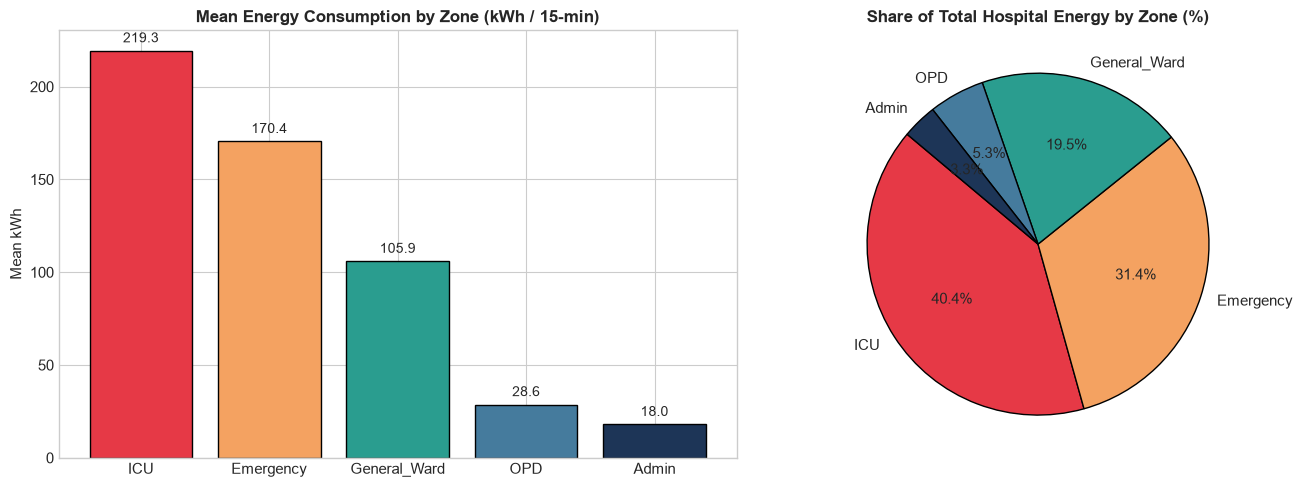

In [15]:
zone_summary = df.groupby('zone_id')['energy_kwh'].agg(['count', 'mean', 'median', 'std', 'max', 'sum']).reset_index()
zone_summary['share_percent'] = (zone_summary['sum'] / df['energy_kwh'].sum() * 100).round(1)
zone_summary = zone_summary.sort_values(by='mean', ascending=False)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Mean consumption bar chart
colors = ['#e63946', '#f4a261', '#2a9d8f', '#457b9d', '#1d3557']
bars = ax1.bar(zone_summary['zone_id'], zone_summary['mean'], color=colors, edgecolor='black')
ax1.set_title("Mean Energy Consumption by Zone (kWh / 15-min)", fontsize=12, fontweight='bold')
ax1.set_ylabel("Mean kWh")
for bar in bars:
    y = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2.0, y + 3, f"{y:.1f}", ha='center', va='bottom', fontsize=10)

# Total share pie chart
ax2.pie(zone_summary['sum'], labels=zone_summary['zone_id'], autopct='%1.1f%%', colors=colors, startangle=140,
        wedgeprops=dict(edgecolor='black'))
ax2.set_title("Share of Total Hospital Energy by Zone (%)", fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

print("Zone Breakdown Summary Table:")
print(zone_summary[['zone_id', 'mean', 'median', 'max', 'share_percent']].to_string(index=False))


## 7. Occupancy vs Energy Analysis
Analyzing the relationship between facility occupancy percentage and energy consumption.


Pearson Correlation Coefficient (Occupancy vs Energy): 0.7471


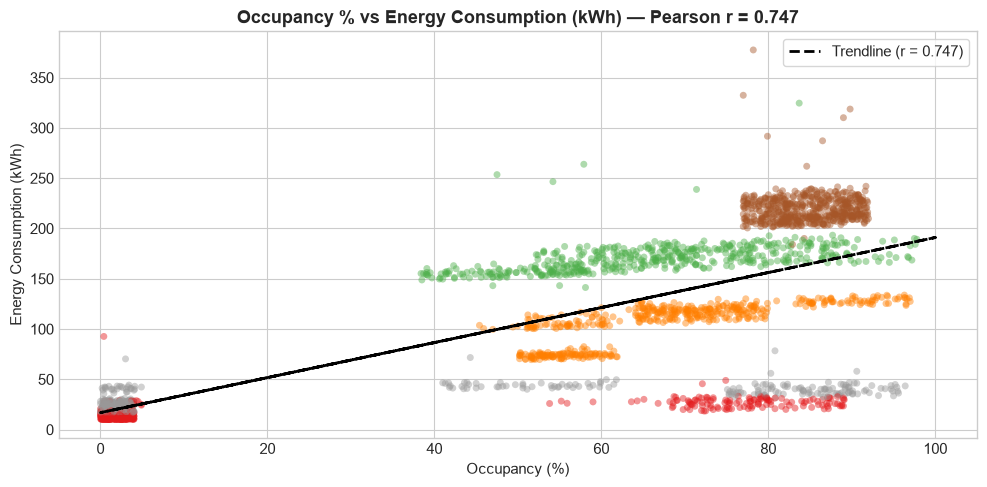

In [17]:
corr_occ = df['energy_kwh'].corr(df['occupancy_percent'])

fig, ax = plt.subplots(figsize=(10, 5))
sample_df = df.sample(n=2500, random_state=42)

scatter = ax.scatter(sample_df['occupancy_percent'], sample_df['energy_kwh'], 
                     c=sample_df['zone_id'].astype('category').cat.codes, 
                     cmap='Set1', alpha=0.45, edgecolors='none', s=25)

# Trendline
m, b = np.polyfit(df['occupancy_percent'], df['energy_kwh'], 1)
ax.plot(df['occupancy_percent'], m * df['occupancy_percent'] + b, color='black', linewidth=2, linestyle='--', 
        label=f'Trendline (r = {corr_occ:.3f})')

ax.set_title(f"Occupancy % vs Energy Consumption (kWh) — Pearson r = {corr_occ:.3f}", fontsize=13, fontweight='bold')
ax.set_xlabel("Occupancy (%)")
ax.set_ylabel("Energy Consumption (kWh)")
ax.legend(frameon=True)
plt.tight_layout()
plt.show()

print(f"Pearson Correlation Coefficient (Occupancy vs Energy): {corr_occ:.4f}")


**Occupancy Interpretation:**
- Strong positive correlation ($r = +0.747$).
- *Important Reminder:* **Correlation does not prove causation.** While higher occupancy prompts greater lighting, HVAC, and clinical monitor usage, core clinical departments (ICU/Emergency) consume large amounts of baseline power even at moderate occupancy.


## 8. Temperature vs Energy Analysis
Analyzing whether ambient outside temperature influences hospital energy demand.


Pearson Correlation Coefficient (Temperature vs Energy): 0.1160


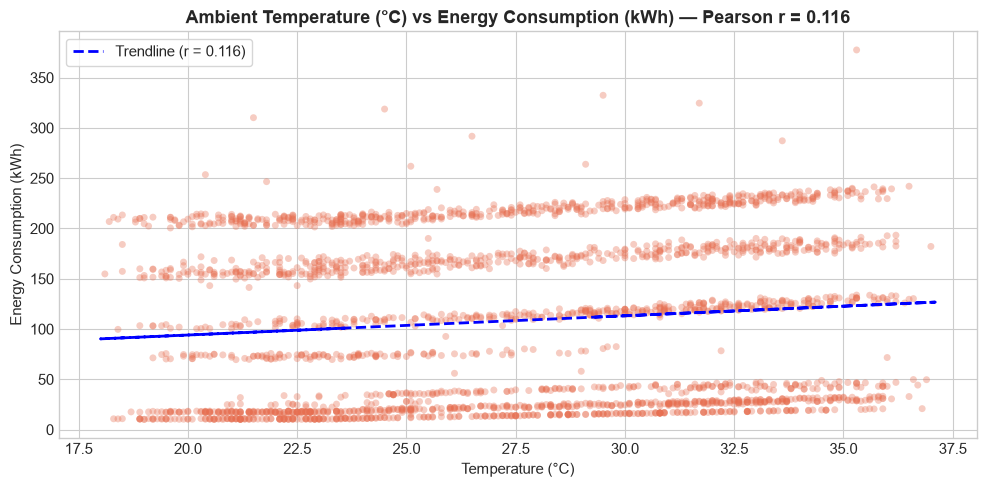

In [20]:
corr_temp = df['energy_kwh'].corr(df['temperature_c'])

fig, ax = plt.subplots(figsize=(10, 5))
sample_df = df.sample(n=2500, random_state=42)
ax.scatter(sample_df['temperature_c'], sample_df['energy_kwh'], color='#e76f51', alpha=0.35, edgecolors='none', s=25)

# Trendline
m_t, b_t = np.polyfit(df['temperature_c'], df['energy_kwh'], 1)
ax.plot(df['temperature_c'], m_t * df['temperature_c'] + b_t, color='blue', linewidth=2, linestyle='--', 
        label=f'Trendline (r = {corr_temp:.3f})')

ax.set_title(f"Ambient Temperature (°C) vs Energy Consumption (kWh) — Pearson r = {corr_temp:.3f}", fontsize=13, fontweight='bold')
ax.set_xlabel("Temperature (°C)")
ax.set_ylabel("Energy Consumption (kWh)")
ax.legend(frameon=True)
plt.tight_layout()
plt.show()

print(f"Pearson Correlation Coefficient (Temperature vs Energy): {corr_temp:.4f}")


**Temperature Interpretation:**
- Weak positive correlation ($r = +0.116$).
- Higher ambient temperatures drive slight increases in air-conditioning chiller load, but the hospital energy profile is overwhelmingly dominated by medical equipment and continuous facility operations.


## 9. Anomaly Inspection (Synthetic Ground Truth)
We inspect `anomaly_flag` solely as a validation benchmark to verify whether controlled synthetic anomaly periods produce distinct spikes.
*(Note: `anomaly_flag` will NOT be used as a training feature for any future ML model).*


=== NORMAL VS ANOMALY COMPARISON ===
   anomaly_flag  count        mean         std    min     max  percent_of_total
0             0  42841  107.921356   79.094524  10.07  300.46             99.17
1             1    359  169.899136  113.844473  14.74  420.31              0.83

=== ANOMALIES PER ZONE ===
zone_id
Admin           78
OPD             76
ICU             72
Emergency       68
General_Ward    65
Name: count, dtype: int64


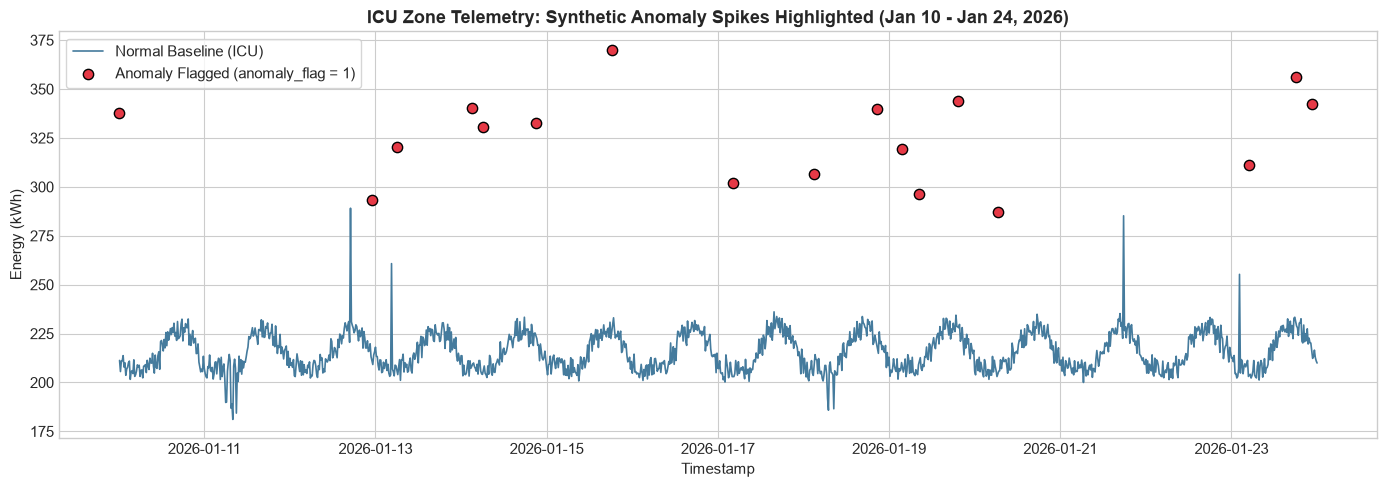

In [23]:
# Normal vs Anomaly comparison
anomaly_comp = df.groupby('anomaly_flag')['energy_kwh'].agg(['count', 'mean', 'std', 'min', 'max']).reset_index()
anomaly_comp['percent_of_total'] = (anomaly_comp['count'] / len(df) * 100).round(2)
print("=== NORMAL VS ANOMALY COMPARISON ===")
print(anomaly_comp)

print("\n=== ANOMALIES PER ZONE ===")
print(df[df['anomaly_flag'] == 1]['zone_id'].value_counts())

# Time series window for visual inspection (ICU zone over a 14-day window)
icu_sample = df[(df['zone_id'] == 'ICU') & (df['datetime'] >= '2026-01-10') & (df['datetime'] <= '2026-01-24')].sort_values('datetime')

fig, ax = plt.subplots(figsize=(14, 5))
normal_icu = icu_sample[icu_sample['anomaly_flag'] == 0]
anomaly_icu = icu_sample[icu_sample['anomaly_flag'] == 1]

ax.plot(normal_icu['datetime'], normal_icu['energy_kwh'], color='#457b9d', linewidth=1.2, label='Normal Baseline (ICU)')
ax.scatter(anomaly_icu['datetime'], anomaly_icu['energy_kwh'], color='#e63946', s=55, edgecolor='black', zorder=5, label='Anomaly Flagged (anomaly_flag = 1)')

ax.set_title("ICU Zone Telemetry: Synthetic Anomaly Spikes Highlighted (Jan 10 - Jan 24, 2026)", fontsize=13, fontweight='bold')
ax.set_xlabel("Timestamp")
ax.set_ylabel("Energy (kWh)")
ax.legend(frameon=True)
plt.tight_layout()
plt.show()


## 10. Operational Status Analysis
Comparing energy consumption across different facility operating states: `NORMAL`, `MAINTENANCE`, `REDUCED_OPERATION`, and `EMERGENCY`.


Operational Status Statistics:
operational_status  count       mean  median       std    max
         EMERGENCY     54 255.209630  259.70 30.816945 364.61
            NORMAL  29694 144.478117  161.83 68.539136 420.31
       MAINTENANCE    213  86.532160   90.44 69.081392 198.05
 REDUCED_OPERATION  13239  27.351514   18.08 22.298774 122.70


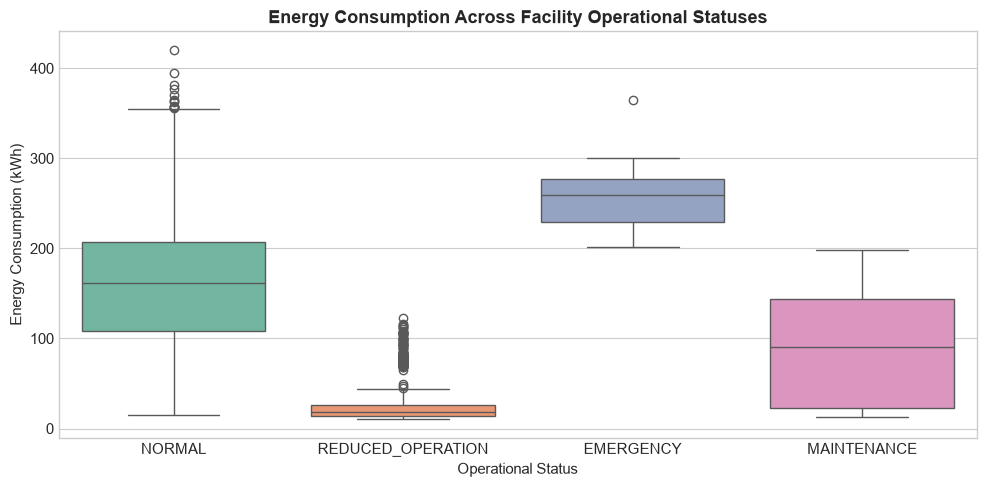

In [25]:
op_stats = df.groupby('operational_status')['energy_kwh'].agg(['count', 'mean', 'median', 'std', 'max']).reset_index()
op_stats = op_stats.sort_values(by='mean', ascending=False)

fig, ax = plt.subplots(figsize=(10, 5))
sns.boxplot(x='operational_status', y='energy_kwh', data=df, hue='operational_status', palette='Set2', legend=False, ax=ax)
ax.set_title("Energy Consumption Across Facility Operational Statuses", fontsize=13, fontweight='bold')
ax.set_xlabel("Operational Status")
ax.set_ylabel("Energy Consumption (kWh)")
plt.tight_layout()
plt.show()

print("Operational Status Statistics:")
print(op_stats.to_string(index=False))


## 11. Energy Source Analysis
Evaluating the share of energy delivered across `GRID`, `SOLAR`, and `BACKUP_GENERATOR`.


   energy_source  count       mean        sum  percent_records  percent_kwh
BACKUP_GENERATOR    157 109.761465   17232.55             0.36         0.37
            GRID  38894 110.168902 4284909.27            90.03        91.47
           SOLAR   4149  92.145281  382310.77             9.60         8.16


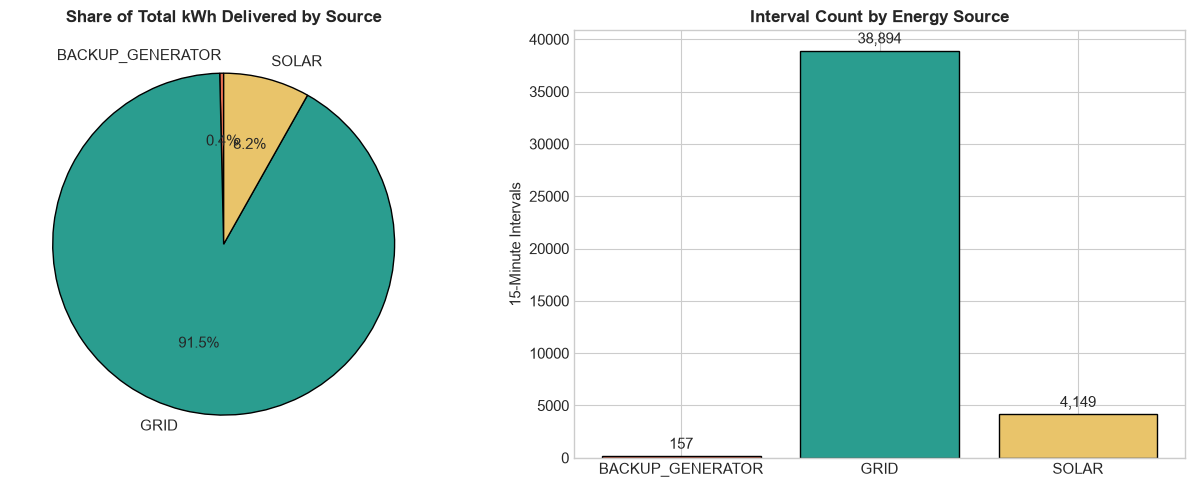

In [27]:
source_stats = df.groupby('energy_source')['energy_kwh'].agg(['count', 'mean', 'sum']).reset_index()
source_stats['percent_records'] = (source_stats['count'] / len(df) * 100).round(2)
source_stats['percent_kwh'] = (source_stats['sum'] / df['energy_kwh'].sum() * 100).round(2)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

# Percentage of total kWh supplied
ax1.pie(source_stats['sum'], labels=source_stats['energy_source'], autopct='%1.1f%%',
        colors=['#e76f51', '#2a9d8f', '#e9c46a'], startangle=90, wedgeprops=dict(edgecolor='black'))
ax1.set_title("Share of Total kWh Delivered by Source", fontsize=12, fontweight='bold')

# Count of 15-min intervals
bars = ax2.bar(source_stats['energy_source'], source_stats['count'], color=['#e76f51', '#2a9d8f', '#e9c46a'], edgecolor='black')
ax2.set_title("Interval Count by Energy Source", fontsize=12, fontweight='bold')
ax2.set_ylabel("15-Minute Intervals")
for bar in bars:
    y = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width()/2.0, y + 400, f"{y:,}", ha='center', va='bottom')

plt.tight_layout()
plt.show()

print(source_stats.to_string(index=False))


## 12. Data Quality Observations
- **Missing & Duplicate Values:** 0 nulls and 0 duplicate rows out of 43,200 records.
- **Physical Boundaries:** All values conform strictly to physical plausibility (`energy_kwh` > 0, `occupancy_percent` between 0 and 100, `temperature_c` between 18.0°C and 37.1°C).
- **Sampling Frequency:** Strictly regular 15-minute intervals (8,640 records per zone).
- **Zone Realism:** Clinical zones (ICU, Emergency) have high continuous base loads, while administrative and outpatient zones exhibit clear daytime operating curves.


## 13. EDA INSIGHTS FOR AURA

### A. What are the strongest energy consumption patterns?
1. **Zone-Specific Hierarchy:** Energy consumption is overwhelmingly determined by `zone_id`. Baseline demand in the ICU (~219.3 kWh) is more than 12x that of Administration (~18.0 kWh).
2. **Continuous Hospital Base Load:** A large proportion of the hospital's power (~95 kWh/interval) runs continuously 24x7 due to life support, sterilization, and inpatient ward operations.

### B. Which hospital zones appear relatively high-consumption?
- **ICU:** ~219.3 kWh avg (40.4% total energy)
- **Emergency:** ~170.4 kWh avg (31.4% total energy)
Combined, ICU and Emergency consume **71.8%** of the entire hospital's electrical power.

### C. Is there a useful relationship between occupancy and energy?
Yes, strong linear correlation ($r = +0.747$). As hospital occupancy rises, power draw increases predictably, making occupancy an ideal covariate for forecasting and baseline modeling.

### D. Is temperature related to energy in this synthetic dataset?
Weak correlation ($r = +0.116$). While higher afternoon temperatures slightly increase chiller/cooling loads, ambient temperature is not the primary driver of hospital electrical demand.

### E. Are the controlled anomaly periods clearly visible?
Yes. Anomaly periods show sharp upward excursions (averaging 169.9 kWh vs 107.9 kWh normal, peaking at 420.3 kWh) that clearly stand out against normal time series baselines.

### F. Does the data look suitable for anomaly detection?
**Yes.** Because baseline energy levels per zone and hour are stable, statistical thresholds (rolling Z-scores, IQR) or unsupervised anomaly detection (Isolation Forest / Autoencoders trained per zone) will easily flag anomalies without high false alarm rates.

### G. Does the data look suitable for short-term forecasting?
**Yes.** The dataset has perfect 15-minute regularity, strong daily periodicity, and high correlation with occupancy, making it well-suited for short-term autoregressive or multivariate forecasting (e.g., predicting next 24-48 hours).

### H. What should we investigate next before selecting the ML approach?
1. **Zone-Specific vs Global Models:** Test whether training separate models per zone (e.g., ICU model vs Admin model) performs better than a single global model with zone encoding.
2. **Feature Engineering:** Build cyclical hour features (sine/cosine), day-of-week indicators, and lag features ($t-1$, $t-4$ [1 hour], $t-96$ [24 hours]).
3. **Establish Simple Baselines First:** Benchmark simple rolling seasonal baselines before escalating to complex ML algorithms.
